# Hotel Harmony: Data Insights for Optimized Operations

**Project goal:** Analyze Hotel Operations Analysis using Python to understand booking patterns, reduce cancellations, improve customer satisfaction, and optimize hotel operations and revenue.

1. Open this notebook in Jupyter Notebook
2. Keep `hotel_bookings.csv` in the same folder as this notebook, upload it through the Files panel.
3. Run each cell from top to bottom using **Shift + Enter**.
4. Read the explanation under each section and save your charts/results for your report.

## 1. Import libraries

In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme()

## 2. Load and inspect data

In [130]:
df = pd.read_csv("C:/Users/ankus/Downloads/JobAaj Project/EDA Project/EDA02 Project/hotel_bookings.csv")
print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [131]:
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing values"))
display(df.describe(include="all").T)

,Missing values
company,112593
agent,16340
country,488
children,4
arrival_date_month,0
arrival_date_week_number,0
hotel,0
is_canceled,0
stays_in_weekend_nights,0
arrival_date_day_of_month,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


## 3. Clean the data

In [132]:
hotel = df.copy()
print("Exact duplicate rows:", hotel.duplicated().sum())
hotel = hotel.drop_duplicates().copy()

hotel["children"] = hotel["children"].fillna(0)
hotel["agent"] = hotel["agent"].fillna(0)
hotel["company"] = hotel["company"].fillna(0)

hotel["arrival_date"] = pd.to_datetime(
    hotel["arrival_date_year"].astype(str) + "-" +
    hotel["arrival_date_month"].astype(str) + "-" +
    hotel["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d", errors="coerce"
)
hotel["reservation_status_date"] = pd.to_datetime(
    hotel["reservation_status_date"], errors="coerce"
)
hotel["total_nights"] = hotel["stays_in_week_nights"] + hotel["stays_in_weekend_nights"]
hotel["is_canceled"] = pd.to_numeric(hotel["is_canceled"], errors="coerce")
hotel["adr"] = pd.to_numeric(hotel["adr"], errors="coerce")

print("Rows after cleaning:", len(hotel))
display(hotel.isna().sum().sort_values(ascending=False).head(15).to_frame("Missing after cleaning"))

Exact duplicate rows: 31994
Rows after cleaning: 87396


,Missing after cleaning
country,452
hotel,0
is_canceled,0
lead_time,0
arrival_date_month,0
arrival_date_year,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
arrival_date_week_number,0


# BASIC LEVEL

### Basic 1 — Average booking lead time

In [133]:
print("Average lead time (days):", round(hotel["lead_time"].mean(), 2))

Average lead time (days): 79.89


### Basic 2 — Booking distribution by hotel type

,Bookings
hotel,
City Hotel,53428
Resort Hotel,33968


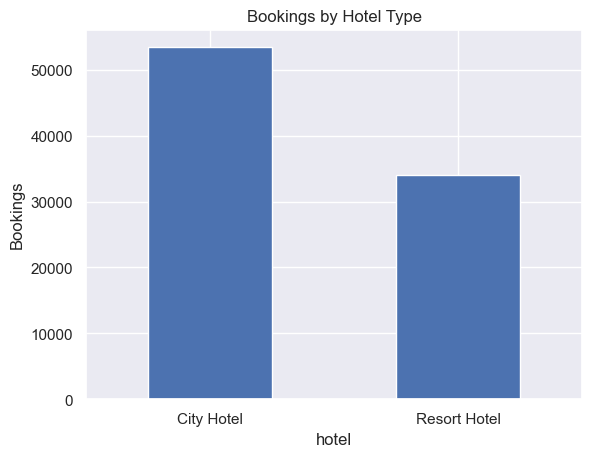

In [134]:
display(hotel["hotel"].value_counts().to_frame("Bookings"))
hotel["hotel"].value_counts().plot(kind="bar")
plt.title("Bookings by Hotel Type"); plt.ylabel("Bookings"); plt.xticks(rotation=0); plt.show()

### Basic 3 — Number of canceled bookings and overall cancellation rate

In [135]:
print("Canceled bookings:", int(hotel["is_canceled"].sum()))
print("Cancellation rate (%):", round(hotel["is_canceled"].mean()*100, 2))

Canceled bookings: 24025
Cancellation rate (%): 27.49


### Basic 4 — Most common arrival month

In [136]:
display(hotel["arrival_date_month"].value_counts().to_frame("Bookings"))
print("Most common month:", hotel["arrival_date_month"].mode().iloc[0])

,Bookings
arrival_date_month,
August,11257
July,10057
May,8355
April,7908
June,7765
March,7513
October,6934
September,6690
February,6098


Most common month: August


### Basic 5 — Average special requests per booking

In [137]:
print("Average special requests:", round(hotel["total_of_special_requests"].mean(), 3))

Average special requests: 0.699


### Basic 6 — Country with the most bookings

In [138]:
country_counts = hotel["country"].value_counts()
display(country_counts.head(10).to_frame("Bookings"))
print("Top country:", country_counts.idxmax())

,Bookings
country,
PRT,27453
GBR,10433
FRA,8837
ESP,7252
DEU,5387
ITA,3066
IRL,3016
BEL,2081
BRA,1995


Top country: PRT


### Basic 7 — Average ADR by hotel type

In [139]:
display(hotel.groupby("hotel")["adr"].mean().to_frame("Average ADR"))

,Average ADR
hotel,
City Hotel,110.985944
Resort Hotel,99.025346


### Basic 8 — Percentage of bookings requiring parking

In [140]:
parking_pct = hotel["required_car_parking_spaces"].gt(0).mean()*100
print(f"Bookings requiring parking: {parking_pct:.2f}%")

Bookings requiring parking: 8.37%


### Basic 9 — Average week-night and weekend-night stays

In [141]:
display(hotel[["stays_in_week_nights","stays_in_weekend_nights"]].mean().to_frame("Average nights"))
print("Average total nights:", round(hotel["total_nights"].mean(), 2))

,Average nights
stays_in_week_nights,2.625395
stays_in_weekend_nights,1.005263


Average total nights: 3.63


### Basic 10 — Bookings made through travel agents

In [142]:
print("Bookings with agent ID recorded:", int(df["agent"].notna().sum()))
print("Bookings with no agent ID recorded:", int(df["agent"].isna().sum()))

Bookings with agent ID recorded: 103050
Bookings with no agent ID recorded: 16340


# MEDIUM LEVEL

### Medium 1 — Cancellation rate by hotel type

In [143]:
display((hotel.groupby("hotel")["is_canceled"].mean()*100).to_frame("Cancellation rate (%)"))

,Cancellation rate (%)
hotel,
City Hotel,30.038557
Resort Hotel,23.480923


### Medium 2 — Average ADR per market segment

In [144]:
display(hotel.groupby("market_segment")["adr"].agg(["mean","median","count"]).sort_values("mean", ascending=False))

,mean,median,count
market_segment,,,
Online TA,118.171606,110.70,51618
Direct,116.579429,106.60,11804
Aviation,100.170396,95.00,227
Offline TA/TO,81.764191,79.05,13889
Groups,74.864284,68.00,4942
Corporate,68.151246,65.00,4212
Undefined,15.000000,15.00,2
Complementary,3.049245,0.00,702


### Medium 3 — Relationship between lead time and cancellation

Correlation: 0.185


,Cancellation rate (%)
lead_time_band,
0-7,8.429851
8-30,25.367197
31-90,32.008442
91-180,34.983281
181-365,39.678571
365+,40.884956


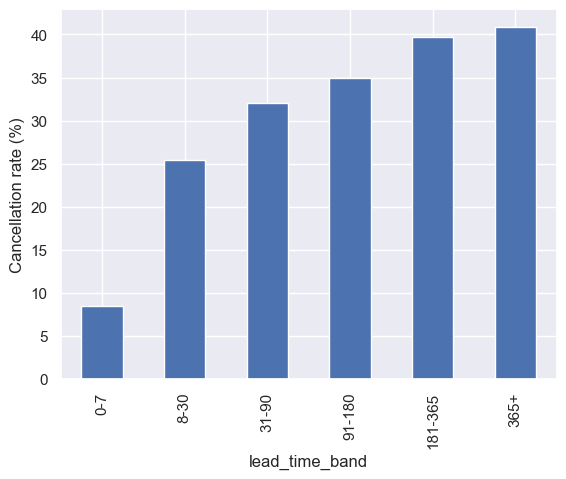

In [145]:
print("Correlation:", round(hotel[["lead_time","is_canceled"]].corr().iloc[0,1], 3))
bins = [-1,7,30,90,180,365,np.inf]
labels = ["0-7","8-30","31-90","91-180","181-365","365+"]
hotel["lead_time_band"] = pd.cut(hotel["lead_time"], bins=bins, labels=labels)
rates = hotel.groupby("lead_time_band", observed=False)["is_canceled"].mean()*100
display(rates.to_frame("Cancellation rate (%)"))
rates.plot(kind="bar"); plt.ylabel("Cancellation rate (%)"); plt.show()

### Medium 4 — Distribution channel with the most bookings

In [146]:
display(hotel["distribution_channel"].value_counts().to_frame("Bookings"))
print("Top channel:", hotel["distribution_channel"].mode().iloc[0])

,Bookings
distribution_channel,
TA/TO,69141
Direct,12988
Corporate,5081
GDS,181
Undefined,5


Top channel: TA/TO


### Medium 5 — Average previous cancellations by hotel type

In [147]:
display(hotel.groupby("hotel")["previous_cancellations"].mean().to_frame("Average previous cancellations"))

,Average previous cancellations
hotel,
City Hotel,0.035768
Resort Hotel,0.021991


### Medium 6 — ADR trend by year

,Average ADR
arrival_date_year,
2015,92.160752
2016,101.538903
2017,118.710660


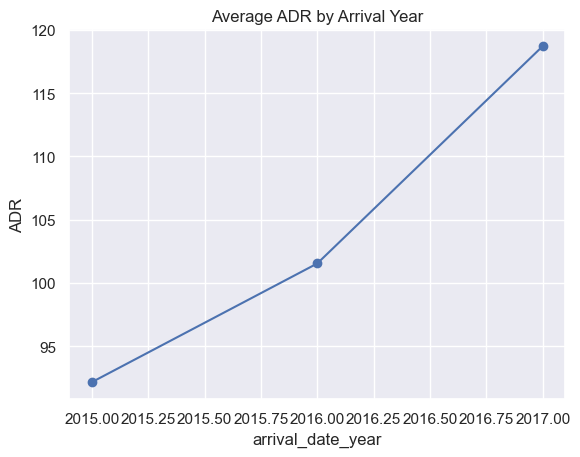

In [148]:
adr_year = hotel.groupby("arrival_date_year")["adr"].mean().sort_index()
display(adr_year.to_frame("Average ADR"))
adr_year.plot(marker="o"); plt.title("Average ADR by Arrival Year"); plt.ylabel("ADR"); plt.show()

### Medium 7 — Month with highest revenue

In [149]:
month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]
hotel["arrival_date_month"] = pd.Categorical(hotel["arrival_date_month"], categories=month_order, ordered=True)
display(hotel.groupby("arrival_date_month", observed=False)["adr"].sum().sort_values(ascending=False).to_frame("Sum of ADR (assignment proxy)"))
hotel["estimated_value_proxy"] = hotel["adr"] * hotel["total_nights"]
display(hotel.groupby("arrival_date_month", observed=False)["estimated_value_proxy"].sum().sort_values(ascending=False).to_frame("ADR x nights proxy"))

,Sum of ADR (assignment proxy)
arrival_date_month,
August,1698412.48
July,1363146.03
June,929859.68
May,929040.10
April,819368.35
September,749823.65
October,625117.56
March,613132.35
February,455472.02


,ADR x nights proxy
arrival_date_month,
August,7240652.99
July,5863024.99
June,3496345.05
May,3123058.22
April,2787157.05
September,2689186.19
March,2048685.33
October,2032649.25
February,1473600.20


### Medium 8 — Impact of special requests on ADR

,mean,median,count
total_of_special_requests,,,
0,99.665633,90.800,43894
1,109.651497,102.600,29017
2,118.570312,112.670,11812
3,125.070790,119.000,2317
4,131.088687,121.015,320
5,129.980000,110.440,36


Correlation: 0.138


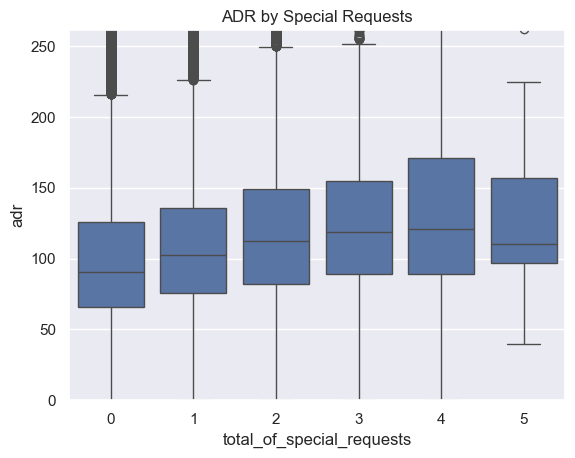

In [150]:
display(hotel.groupby("total_of_special_requests")["adr"].agg(["mean","median","count"]))
print("Correlation:", round(hotel[["total_of_special_requests","adr"]].corr().iloc[0,1], 3))
sns.boxplot(data=hotel, x="total_of_special_requests", y="adr")
plt.ylim(hotel["adr"].quantile(.01), hotel["adr"].quantile(.99))
plt.title("ADR by Special Requests"); plt.show()

### Medium 9 — Average stay duration: repeated vs new guests

In [151]:
hotel["guest_group"] = hotel["is_repeated_guest"].map({0:"New guest",1:"Repeated guest"})
display(hotel.groupby("guest_group")["total_nights"].agg(["mean","median","count"]))

,mean,median,count
guest_group,,,
New guest,3.699932,3.0,83981
Repeated guest,1.927086,1.0,3415


### Medium 10 — Most booked reserved room type

,Bookings
reserved_room_type,
A,56552
D,17398
E,6049
F,2823
G,2052
B,999
C,915
H,596
L,6


Most common room type: A


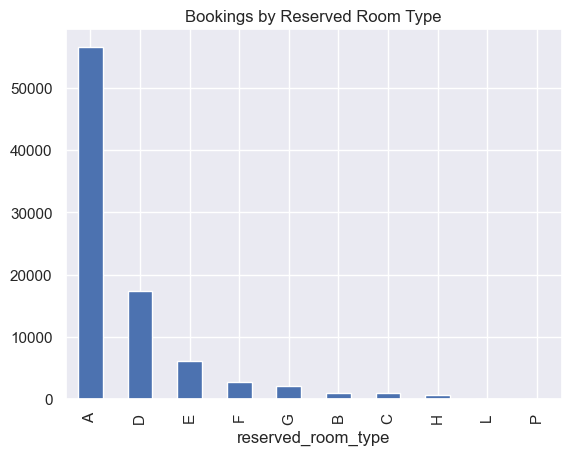

In [152]:
display(hotel["reserved_room_type"].value_counts().to_frame("Bookings"))
print("Most common room type:", hotel["reserved_room_type"].mode().iloc[0])
hotel["reserved_room_type"].value_counts().plot(kind="bar")
plt.title("Bookings by Reserved Room Type"); plt.show()

# ADVANCED LEVEL

### Advanced 1 — Factors associated with cancellation (logistic regression)

In [153]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

features = ["lead_time","booking_changes","total_of_special_requests",
            "previous_cancellations","is_repeated_guest","adults","children",
            "babies","adr","total_nights","hotel","market_segment",
            "distribution_channel","deposit_type","customer_type","reserved_room_type"]
data = hotel[features + ["is_canceled"]].dropna(subset=["is_canceled"]).copy()
X, y = data[features], data["is_canceled"].astype(int)
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])
model = Pipeline([("prep", preprocess),
                  ("logreg", LogisticRegression(max_iter=1000, class_weight="balanced"))])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.2, random_state=42, stratify=y)
model.fit(X_train, y_train)
pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:,1]
print(classification_report(y_test, pred))
print("ROC-AUC:", round(roc_auc_score(y_test, prob), 3))

              precision    recall  f1-score   support

           0       0.86      0.69      0.76     12675
           1       0.46      0.71      0.56      4805

    accuracy                           0.69     17480
   macro avg       0.66      0.70      0.66     17480
weighted avg       0.75      0.69      0.71     17480

ROC-AUC: 0.762


#### View the largest logistic-regression coefficients

In [154]:
names = model.named_steps["prep"].get_feature_names_out()
coefs = model.named_steps["logreg"].coef_[0]
coef_table = pd.DataFrame({"feature": names, "coefficient": coefs})
display(coef_table.reindex(coef_table["coefficient"].abs().sort_values(ascending=False).index).head(20))

,feature,coefficient
26,cat__deposit_type_Non Refund,2.367706
41,cat__reserved_room_type_P,2.125241
24,cat__distribution_channel_Undefined,1.791617
25,cat__deposit_type_No Deposit,-1.301504
17,cat__market_segment_Offline TA/TO,-1.059445
19,cat__market_segment_Undefined,0.952489
22,cat__distribution_channel_GDS,-0.651790
27,cat__deposit_type_Refundable,-0.640475
30,cat__customer_type_Transient,0.610139
2,num__total_of_special_requests,-0.523109


### Advanced 2 — ADR variation by adults, children, and babies

In [155]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

reg_data = hotel[["adults","children","babies","adr"]].dropna()
Xr = reg_data[["adults","children","babies"]]
yr = reg_data["adr"]
Xtr, Xte, ytr, yte = train_test_split(Xr, yr, test_size=.2, random_state=42)
reg = LinearRegression().fit(Xtr, ytr)
yp = reg.predict(Xte)
display(pd.DataFrame({"feature": Xr.columns, "coefficient": reg.coef_}))
print("Intercept:", round(reg.intercept_, 3))
print("R²:", round(r2_score(yte, yp), 3))
print("MAE:", round(mean_absolute_error(yte, yp), 3))

,feature,coefficient
0,adults,20.027930
1,children,38.409629
2,babies,6.923331


Intercept: 63.183
R²: 0.203
MAE: 35.617


### Advanced 3 — Relationship between booking changes and special requests

Correlation: 0.016


,mean,median,count
booking_changes,,,
0,0.696562,1.0,71494
1,0.681985,0.0,10902
2,0.737172,0.0,3508
3,0.826286,1.0,875
4,0.820225,0.0,356
5,0.836207,1.0,116
6,0.864407,1.0,59
7,0.645161,1.0,31
8,0.882353,0.0,17


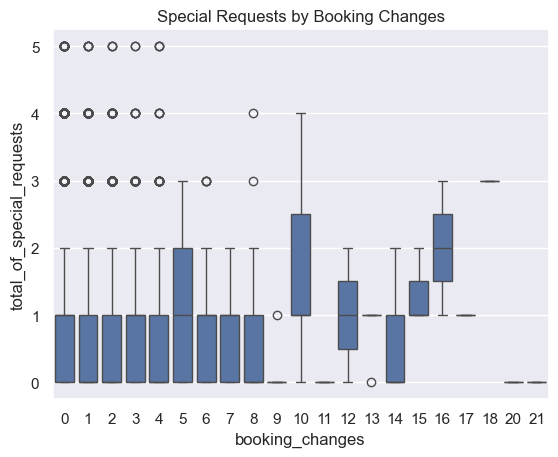

In [156]:
print("Correlation:", round(hotel[["booking_changes","total_of_special_requests"]].corr().iloc[0,1], 3))
display(hotel.groupby("booking_changes")["total_of_special_requests"].agg(["mean","median","count"]).head(15))
sns.boxplot(data=hotel, x="booking_changes", y="total_of_special_requests")
plt.title("Special Requests by Booking Changes"); plt.show()

### Advanced 4 — Seasonal impact on cancellations

,Cancellation rate (%)
arrival_date_month,
January,22.118048
February,23.204329
March,24.357780
April,30.462822
May,29.228007
June,30.315518
July,31.798747
August,32.184419
September,24.544096


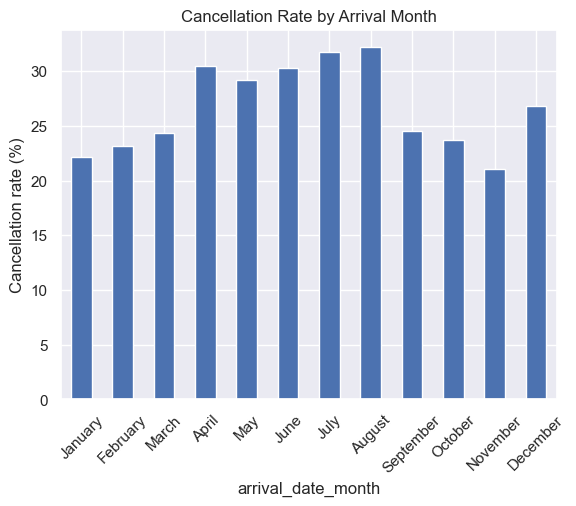

In [157]:
cancel_month = hotel.groupby("arrival_date_month", observed=False)["is_canceled"].mean()*100
display(cancel_month.to_frame("Cancellation rate (%)"))
cancel_month.plot(kind="bar"); plt.ylabel("Cancellation rate (%)"); plt.title("Cancellation Rate by Arrival Month"); plt.xticks(rotation=45); plt.show()

### Advanced 5 — Lead-time distribution by market segment

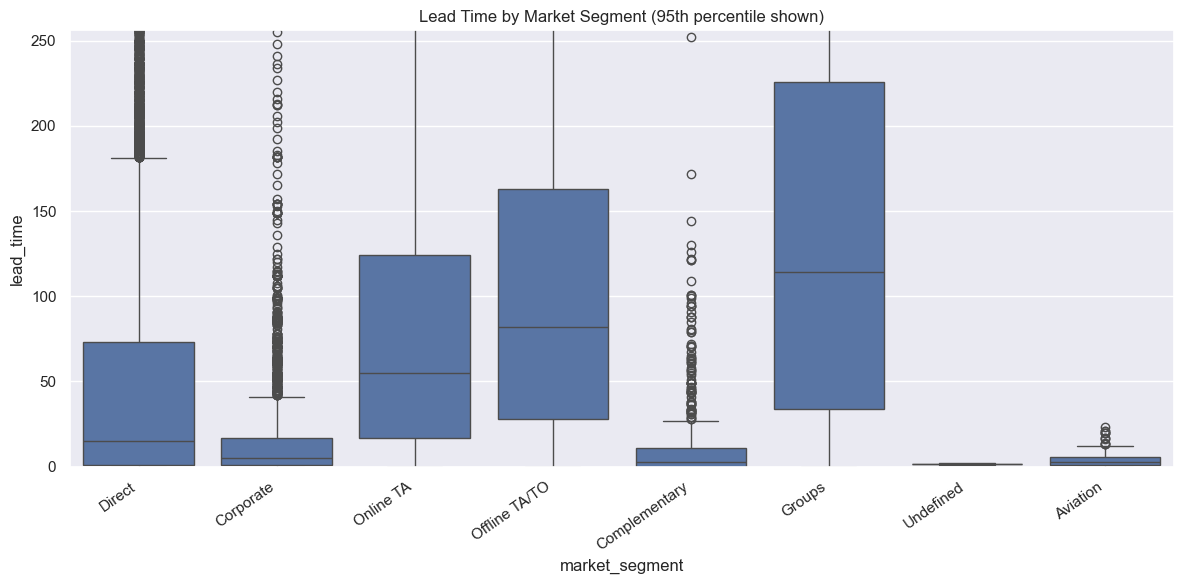

,mean,median,count
market_segment,,,
Groups,147.605423,114.0,4942
Offline TA/TO,106.052416,82.0,13889
Online TA,79.902805,55.0,51618
Direct,48.825059,15.0,11804
Corporate,16.252849,5.0,4212
Complementary,13.635328,3.0,702
Aviation,4.281938,3.0,227
Undefined,1.500000,1.5,2


In [158]:
plt.figure(figsize=(12,6))
sns.boxplot(data=hotel, x="market_segment", y="lead_time")
plt.ylim(0, hotel["lead_time"].quantile(.95))
plt.title("Lead Time by Market Segment (95th percentile shown)")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()
display(hotel.groupby("market_segment")["lead_time"].agg(["mean","median","count"]).sort_values("mean", ascending=False))

## Save cleaned data

In [159]:
hotel.to_csv("hotel_bookings_cleaned.csv", index=False)
print("Saved hotel_bookings_cleaned.csv")

Saved hotel_bookings_cleaned.csv
